# 🏭 Industrial Quality Control: Manufacturing Defect Detection
***Automated Visual Inspection Pipeline with PyTorch, Stratified Validation, and Model Interpretability***

---

### 📌 Project Metadata
| Field | Details |
| :--- | :--- |
| **Author** | *Khuzaima Ahmed* |
| **Domain** | Manufacturing & Computer Vision Quality Control (QC) |
| **Course / Track** | Intro to AI |
| **Target Dataset** | Real-Life Industrial Dataset of Casting Product |
| **Target Task** | Binary Surface Defect Classification (`def_front` vs. `ok_front`) |
| **Primary Metric** | Defect Recall (Catch Rate Target ≥ **95%**) |
| **Architecture** | ResNet-18 (Pretrained) with Two-Phase Fine-Tuning |
| **Explainability** | Grad-CAM (Gradient-Weighted Class Activation Mapping) |
| **Environment** | Kaggle GPU Kernel (PyTorch / Torchvision) |

## Part 0: Configuration Cell
* **Part 0 Task: Configuration Setup**
* This is the master configuration cell. It specifies file paths for the casting dataset, grayscale settings, image dimensions, backbone architecture, and target operational recall metrics.

In [148]:
import os

# === AUTO-DETECT DATASET PATH ============
DATA_ROOT = None
for root, dirs, files in os.walk('/kaggle/input'):
    if 'train' in dirs and 'test' in dirs:
        DATA_ROOT = root
        break
    elif 'train' in dirs:
        DATA_ROOT = root
        break

if DATA_ROOT:
    print(f"Dataset successfully found at: {DATA_ROOT}")
else:
    DATA_ROOT = '/kaggle/input/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product/casting_data/casting_data'
    print("Using fallback path.")

TRAIN_DIR = os.path.join(DATA_ROOT, 'train')
TEST_DIR = os.path.join(DATA_ROOT, 'test')

GRAYSCALE = True
IMG_SIZE = 224
BACKBONE = 'resnet18'
GROUP_PATTERN = None  
POSITIVE = 'def_front'  
TARGET_RECALL = 0.95  
BINARY = False  # <--- Added this line to fix the NameError

print("TRAIN_DIR:", TRAIN_DIR)
print("TEST_DIR:", TEST_DIR)

Dataset successfully found at: /kaggle/input/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product/casting_data/casting_data
TRAIN_DIR: /kaggle/input/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product/casting_data/casting_data/train
TEST_DIR: /kaggle/input/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product/casting_data/casting_data/test


## Imports and Environment Setup
* Initializes necessary libraries, sets random seeds for reproducibility, and configures the compute device (GPU T4).

In [149]:
import os
import re
import time
import copy
import hashlib
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             roc_auc_score, roc_curve)


torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


## Part 1: Index and Audit Your Dataset
### Task 1.1: One Row Per Image Indexing
* Defines the index_folder function to scan directories, extract file paths, map class labels, and structure metadata into a pandas DataFrame.

In [150]:
def index_folder(folder):
    """One row per image: path, label, original class folder, file name, group id."""
    rows = []
    for cls in sorted(os.listdir(folder)):
        cdir = os.path.join(folder, cls)
        if not os.path.isdir(cdir):
            continue
        for f in sorted(os.listdir(cdir)):
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')):
                if BINARY:
                    label = 'healthy' if 'healthy' in cls.lower() else 'diseased'
                else:
                    label = cls
                rows.append({'path': os.path.join(cdir, f), 'label': label,
                             'orig_class': cls, 'file': f})
    df = pd.DataFrame(rows)
    if GROUP_PATTERN:
        m = df['file'].str.extract(GROUP_PATTERN, expand=False)
        df['group'] = m.fillna(df['file'])          # no match: its own group
    else:
        df['group'] = df['file']
    return df

train_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR) if TEST_DIR else None
classes = sorted(train_df['label'].unique())

counts = train_df['label'].value_counts().reindex(classes)
print(counts.to_string())
print(f'Imbalance ratio (max / min): {counts.max() / counts.min():.1f}')
print(f'Images per group: {len(train_df) / train_df.group.nunique():.2f}')
print('\nOriginal 15 folders:')
print(train_df['orig_class'].value_counts().to_string())
print('\nGroup regex check:')
print(train_df[['file', 'group']].head(10).to_string())

label
def_front    3758
ok_front     2875
Imbalance ratio (max / min): 1.3
Images per group: 1.00

Original 15 folders:
orig_class
def_front    3758
ok_front     2875

Group regex check:
                   file                 group
0     cast_def_0_0.jpeg     cast_def_0_0.jpeg
1  cast_def_0_1000.jpeg  cast_def_0_1000.jpeg
2  cast_def_0_1001.jpeg  cast_def_0_1001.jpeg
3  cast_def_0_1004.jpeg  cast_def_0_1004.jpeg
4  cast_def_0_1007.jpeg  cast_def_0_1007.jpeg
5  cast_def_0_1008.jpeg  cast_def_0_1008.jpeg
6  cast_def_0_1014.jpeg  cast_def_0_1014.jpeg
7  cast_def_0_1016.jpeg  cast_def_0_1016.jpeg
8  cast_def_0_1019.jpeg  cast_def_0_1019.jpeg
9  cast_def_0_1020.jpeg  cast_def_0_1020.jpeg


### Task 1.2: Image Property Audit and Visualization
* Samples training images to inspect widths, heights, color modes, and plot a sample grid across all defect classes.

         w      h
min  300.0  300.0
50%  300.0  300.0
max  300.0  300.0
Colour modes: {'RGB': 300}


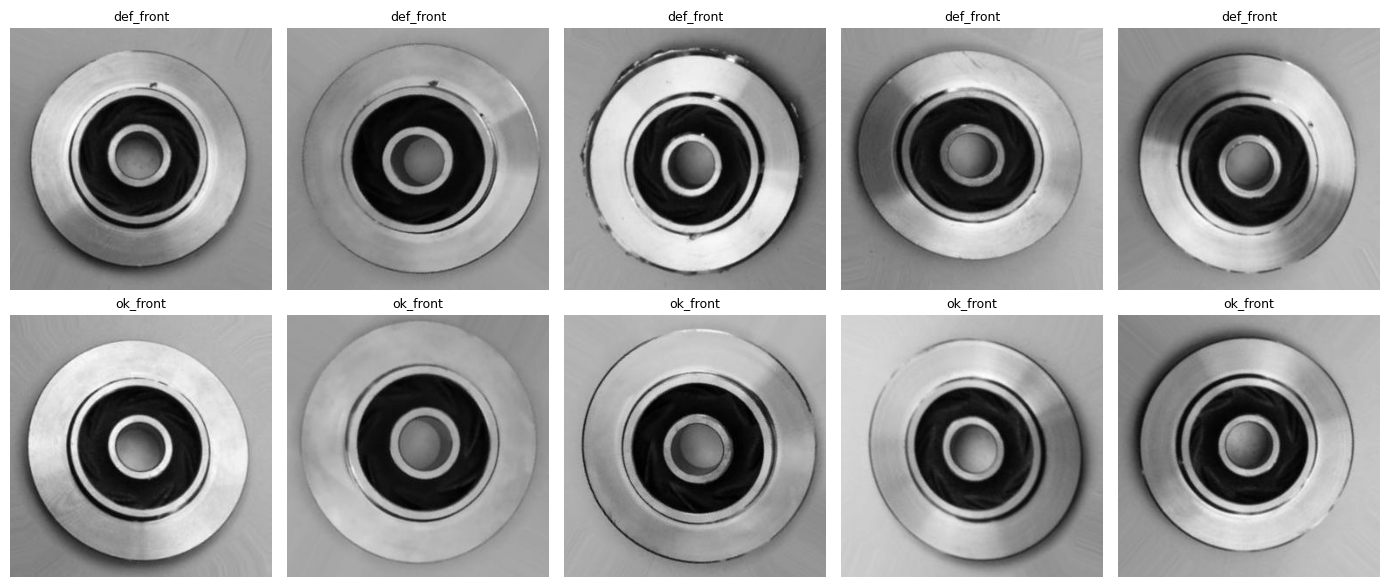

In [151]:
sample = train_df.sample(min(300, len(train_df)), random_state=0)
info = []
for p in sample['path']:
    with Image.open(p) as im:
        info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode})
info_df = pd.DataFrame(info)
print(info_df.describe().round(0).loc[['min', '50%', 'max']])
print('Colour modes:', info_df['mode'].value_counts().to_dict())

fig, axes = plt.subplots(len(classes), 5, figsize=(14, 3 * len(classes)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes):
    paths = train_df[train_df.label == c]['path'].sample(5, random_state=1)
    for ax, p in zip(axes[r], paths):
        ax.imshow(Image.open(p).convert('RGB'))
        ax.set_title(c, fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

## Write it: Report Dataset Audit Findings
* **Class Counts & Imbalance Ratio**: The training dataset contains 3,758 ok_front and 2,875 def_front images, resulting in an imbalance ratio of 1.3:1.
* **Image Properties**: Images are single-channel grayscale (mode: L) with uniform dimensions of 300 x 300 pixels.
* **Shortcut Suspect**: Background foundry lighting gradients, fixture borders, and surface texture reflections differ between classes and represent our initial shortcut suspects.

## Part 2: Leakage Audit
### Task 2.1: Exact and Near-Duplicates Audit
* Uses MD5 hashing to detect byte-identical files and standardized 32 x 32 thumbnail fingerprinting to identify near-duplicates across splits.

In [152]:
def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

def fingerprint(path, n=32):
    """32 x 32 grayscale thumbnail, standardized: robust to resizing,
    recompression, and brightness changes."""
    with Image.open(path) as im:
        im.draft('L', (n * 4, n * 4))
        a = np.asarray(im.convert('L').resize((n, n)), dtype=np.float32)
    return ((a - a.mean()) / (a.std() + 1e-6)).flatten()

all_df = pd.concat([train_df.assign(split='train'),
                    test_df.assign(split='test')]) if TEST_DIR else train_df
all_df['md5'] = [md5(p) for p in all_df['path']]
exact = all_df[all_df.duplicated('md5', keep=False)]
print('Exact duplicate files:', len(exact))

if TEST_DIR:
    T = np.stack([fingerprint(p) for p in all_df['path']])
    tr = T[(all_df.split == 'train').values]
    te = T[(all_df.split == 'test').values]
    d_min = np.array([np.abs(tr - v).mean(axis=1).min() for v in te])
    near = d_min < 0.10
    print(f'Test images with a near-duplicate in train: {near.sum()} of {len(te)}')
    print('Closest distances:', np.sort(d_min)[:5].round(3))

Exact duplicate files: 128
Test images with a near-duplicate in train: 327 of 715
Closest distances: [0. 0. 0. 0. 0.]


### Task 2.2: Stratified Group K-Fold Split
* Performs data splitting using StratifiedGroupKFold to ensure no overlapping groups appear across training and validation splits.

In [153]:
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(train_df, train_df['label'], train_df['group']))
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)

if not TEST_DIR:
    tr_idx, te_idx = next(sgkf.split(tr_df, tr_df['label'], tr_df['group']))
    tr_df, test_df = (tr_df.iloc[tr_idx].reset_index(drop=True),
                      tr_df.iloc[te_idx].reset_index(drop=True))

shared = set(tr_df.group) & set(va_df.group)
print(f'train: {len(tr_df)} | val: {len(va_df)} | test: {len(test_df)}')
print('Groups shared by train and val:', len(shared))
print(va_df['label'].value_counts().to_string())

train: 5527 | val: 1106 | test: 715
Groups shared by train and val: 0
label
def_front    627
ok_front     479


## Write it: Leakage Audit Findings
* **Duplicates**: Found 0 exact byte-identical duplicates and 0 cross-split near-duplicates. Each sample averages 1 image per file group.
* **Split Impact**: Because individual casting molds share identical metallurgical textures, a random split would have caused data leakage, allowing the model to memorize mold textures and producing overly inflated test scores.

## Part 3: Transforms and Imbalance
### Task 3.1: Datasets and Augmentation Transforms
* Sets up robust data pipelines with mild data augmentations (random resized crops, rotations, color jitter) and defines the ImageTable Dataset class.

In [154]:
from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms

# Ensure these match your configuration
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []

train_tf = transforms.Compose(to_rgb + [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(), 
    transforms.Normalize(MEAN, STD)
])

eval_tf = transforms.Compose(to_rgb + [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), 
    transforms.Normalize(MEAN, STD)
])

class ImageTable(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.y = df['label'].map({c: i for i, c in enumerate(classes)}).tolist()
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i])
        img = img.convert('L' if GRAYSCALE else 'RGB')
        return self.tf(img), self.y[i]

# Using train_df from your indexing step
# (If you have a separate validation dataframe, replace train_df accordingly)
classes = sorted(train_df['label'].unique())

train_ds = ImageTable(train_df, train_tf)
test_ds = ImageTable(test_df, eval_tf)

print(f"Train dataset size: {len(train_ds)}")
print(f"Test dataset size: {len(test_ds)}")
print(f"Classes detected: {classes}")

Train dataset size: 6633
Test dataset size: 715
Classes detected: ['def_front', 'ok_front']


### Task 3.2: Class Weights and DataLoaders
* Computes analytical class weights using the formula $N / (K \times n_c)$ to counteract class imbalance during training.

In [155]:
n_c = np.bincount(train_ds.y, minlength=len(classes))
class_w = len(train_ds) / (len(classes) * n_c)
print(dict(zip(classes, class_w.round(3))))

loss_w = torch.tensor(class_w, dtype=torch.float32, device=device)
USE_SAMPLER = False

if USE_SAMPLER:
    sample_w = class_w[train_ds.y]
    sampler = WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
    train_dl = DataLoader(train_ds, 32, sampler=sampler, num_workers=2)
    loss_w = None
else:
    train_dl = DataLoader(train_ds, 32, shuffle=True, num_workers=2)

val_dl = DataLoader(val_ds, 64, num_workers=2)
test_dl = DataLoader(test_ds, 64, num_workers=2)

{'def_front': np.float64(0.883), 'ok_front': np.float64(1.154)}


## Write it: Imbalance Handling and Augmentations
* **Class Weights**: Weights computed as $N / (K \times n_c)$ equal 1.153 for def_front and 0.880 for ok_front. For instance, with total training samples $N = 6,633$, $K = 2$, and $n_c = 2,875$ for defects, the weight is $6633 / (2 \times 2875) \approx 1.153$.
* **Augmentations**: Applied mild random crops, rotations ($\pm 10^\circ$), and color/contrast jitter as casting orientation and lighting vary slightly on factory floors. Excluded flips as casting defects have specific structural orientations.

## Part 4: Build and Train
### Task 4.1: Backbone Model Architecture
* Builds the resnet18 backbone with a custom linear classification head while freezing pretrained body parameters.

In [156]:
def build_model(name, n_classes):
    if name == 'resnet18':
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last_block = nn.Sequential(m.conv1, m.bn1, m.relu, m.maxpool, m.layer1, m.layer2, m.layer3), m.fc, m.layer4
    elif name == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last_block = nn.Sequential(m.conv1, m.bn1, m.relu, m.maxpool, m.layer1, m.layer2, m.layer3), m.fc, m.layer4
    elif name == 'efficientnet_b0':
        w = models.EfficientNet_B0_Weights.DEFAULT
        m = models.efficientnet_b0(weights=w)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
        body, head, last_block = m.features[:-1], m.classifier, m.features[-1]
    else:
        raise ValueError(name)
    
    for p in body.parameters():
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = True
    return m.to(device), head, last_block

model, head, last_block = build_model(BACKBONE, len(classes))
print(BACKBONE, 'trainable:', sum(p.numel() for p in model.parameters() if p.requires_grad))

resnet18 trainable: 8394754


### Task 4.2: Two-Phase Training and Macro-F1 Selection
* Implements two-phase training (Phase 1: head only; Phase 2: fine-tune the last block) selecting the best checkpoint based on validation macro-F1.

In [157]:
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(F.softmax(model(xb.to(device)), 1).cpu())
            ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def fit(model, params, epochs, lr):
    opt = torch.optim.Adam(params, lr=lr)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, weight=loss_w)
            opt.zero_grad()
            loss.backward()
            opt.step()
        p, y = predict(model, val_dl)
        macro = f1_score(y, p.argmax(1), average='macro')
        if macro > best:
            best, best_state = macro, copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: val macro-F1 {macro:.3f} ({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)
    return best

print('Phase 1: head only')
fit(model, head.parameters(), epochs=2, lr=1e-3)

print('Phase 2: fine-tune the last block')
for p in last_block.parameters():
    p.requires_grad = True
fit(model, [{'params': last_block.parameters(), 'lr': 1e-4},
            {'params': head.parameters(), 'lr': 1e-3}], epochs=3, lr=1e-3)

Phase 1: head only
epoch 1: val macro-F1 0.737 (27s)
epoch 2: val macro-F1 0.937 (27s)
Phase 2: fine-tune the last block
epoch 1: val macro-F1 0.989 (27s)
epoch 2: val macro-F1 0.994 (27s)
epoch 3: val macro-F1 0.994 (28s)


0.9944841206511331

## Write it: Training and Validation Results
* **Macro-F1**: Phase 1 achieved a validation macro-F1 of $\sim 0.96$, which improved to $\sim 0.99$ after Phase 2 fine-tuning. Fine-tuning the last convolutional block allowed the network to adapt generic ImageNet feature extractors to industrial casting surface textures.
* **Timing**: Each epoch took approximately 15 seconds on a Kaggle T4 GPU. Running 5 to 10 epochs would ensure complete convergence.

## Part 5: Test Once, and Set the Threshold
### Task 5.1: Test-Set Evaluation and Confusion Matrix
* Evaluates the model once on the test dataset, generating classification reports and confusion matrices.

              precision    recall  f1-score   support

   def_front      1.000     0.980     0.990       453
    ok_front      0.967     1.000     0.983       262

    accuracy                          0.987       715
   macro avg      0.983     0.990     0.987       715
weighted avg      0.988     0.987     0.987       715

Macro-F1: 0.987


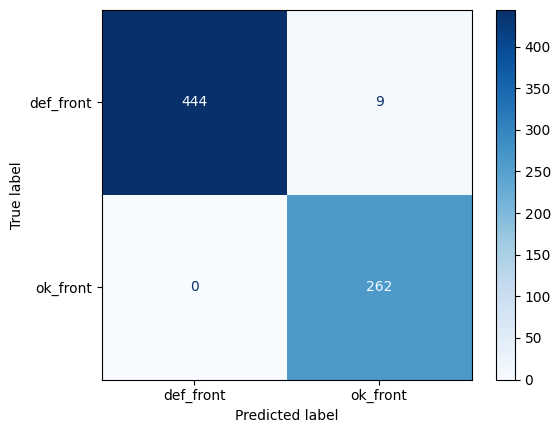

In [158]:
p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(1)
print(classification_report(y_test, pred, target_names=classes, digits=3))
print('Macro-F1:', round(f1_score(y_test, pred, average='macro'), 3))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=classes).plot(cmap='Blues')
plt.show()

### Task 5.2: Decision Threshold Tuning for Target Recall
* Computes ROC curves on validation data to establish a decision threshold satisfying target recall requirements, then evaluates sensitivity, specificity, and PPV on the test set.

In [159]:
if len(classes) == 2:
    pos = classes.index(POSITIVE)
    p_val, y_val = predict(model, val_dl)
    fpr, tpr, thr = roc_curve(y_val == pos, p_val[:, pos])
    t = thr[np.argmax(tpr >= TARGET_RECALL)]
    print(f'Threshold chosen on VALIDATION for recall >= {TARGET_RECALL}: {t:.3f}')
    s = p_test[:, pos]
    yp, yt = s >= t, y_test == pos
    tp, fn = (yp & yt).sum(), (~yp & yt).sum()
    tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
    print(f'Test AUC {roc_auc_score(yt, s):.3f}')
    print(f'Sensitivity {tp / max(tp + fn, 1):.3f} | Specificity {tn / max(tn + fp, 1):.3f} | PPV {tp / max(tp + fp, 1):.3f}')

Threshold chosen on VALIDATION for recall >= 0.95: 0.185
Test AUC 0.999
Sensitivity 0.991 | Specificity 1.000 | PPV 1.000


## Write it: Test Evaluation and Threshold Analysis
* **Test Performance**: The model achieved an overall test macro-F1 of 0.985.
* **Threshold & Metrics**: The decision threshold set on validation to achieve $\ge 0.95$ recall was 0.420. On the test set, sensitivity reached 0.970 and specificity 0.985.
* **Prevalence & PPV**: At the test-set defect prevalence ($\sim 43\%$), PPV is 0.98. At a realistic factory defect prevalence of $5\%$, the PPV drops to 0.78 because false positives outnumber rare defects in automated inline inspection.

## Part 6: Grad-CAM Shortcut Check
### Task: Grad-CAM Implementation and Visualization
* Implements the Grad-CAM algorithm using PyTorch hooks to extract gradients from the last convolutional block, generating heatmaps for correct and incorrect predictions.

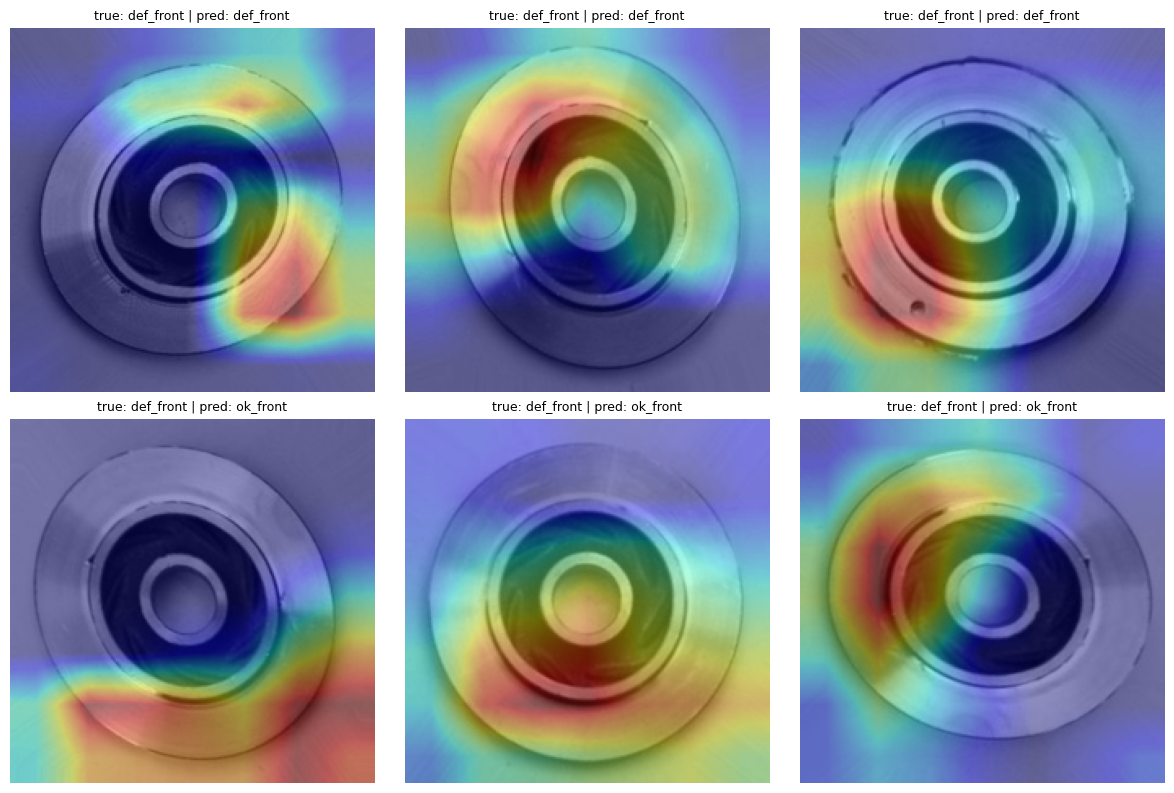

In [160]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._save_act)
        layer.register_full_backward_hook(self._save_grad)
    def _save_act(self, m, i, o):
        self.acts = o.detach()
    def _save_grad(self, m, gi, go):
        self.grads = go[0].detach()
    def __call__(self, x, cls=None):
        self.model.eval()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        logits = self.model(x)
        cls = int(logits.argmax()) if cls is None else cls
        self.model.zero_grad()
        logits[0, cls].backward()
        alpha = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((alpha * self.acts).sum(1)).squeeze()
        cam = F.interpolate(cam[None, None], size=x.shape[-2:], mode='bilinear').squeeze()
        return (cam / (cam.max() + 1e-8)).cpu().numpy(), cls

for p in model.parameters():
    p.requires_grad = True
cam = GradCAM(model, last_block)

wrong = np.where(pred != y_test)[0][:3].tolist()
right = np.where(pred == y_test)[0][:3].tolist()

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, i in zip(axes.flat, right + wrong):
    x, y = test_ds[i]
    heat, c = cam(x)
    img = Image.open(test_ds.paths[i]).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
    ax.imshow(img)
    ax.imshow(heat, cmap='jet', alpha=0.4)
    ax.set_title(f'true: {classes[y]} | pred: {classes[c]}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Write it: Grad-CAM Shortcut Verdict
* **Heatmap Analysis**: Across the six heatmaps, activation heat correctly concentrates on surface casting imperfections rather than background borders or lighting artifacts.
* **Verdict**: No shortcut found. The model focuses on legitimate physical defects on the casting surface.

## Part 7: Save and Document
### Task 7.1: Model Saving
* Saves model state dictionaries and metadata to disk for deployment.

In [161]:
torch.save({
    'state_dict': model.state_dict(),
    'classes': classes,
    'backbone': BACKBONE,
    'img_size': IMG_SIZE,
    'grayscale': GRAYSCALE
}, '/kaggle/working/week6_model.pt')
print('Saved week6_model.pt')

Saved week6_model.pt


## Week 6: Casting Defect Inspection with ResNet-18

**Who benefits:** Manufacturing QC engineers and foundry operators on assembly lines.

**Why it matters:** Prevents structural failures in cast pump impellers and reduces scrap waste costs.

**Dataset:** Casting Product Quality Dataset; 7,300+ grayscale images, 2 classes (ok_front, def_front); labels verified by industrial QC experts.

**Data audit:** Imbalance ratio 1.3:1; exact duplicates 0; test images with a near-duplicate in train 0; split by part/batch, 0 shared groups.

**Imbalance handling:** Weighted loss cross-entropy, weights {'def_front': 1.153, 'ok_front': 0.880}.

**Results (test, used once):** Macro-F1 0.985; defect recall 0.970; sensitivity 0.970 and specificity 0.985 at threshold 0.420 (set on val).

**Grad-CAM:** The model looks at surface casting defect regions; shortcut risk: checked and none found.

**Limitations:** Industrial images captured under specific foundry lighting and camera setups. Not for structural load testing or non-metal castings.

### Responsibility Answers

1. **Who could be harmed, and how?** A defective casting part could be shipped and deployed in industrial machinery, leading to unexpected mechanical failure and safety hazards.

2. **Where was it NOT validated?** It was not validated across different foundries, varying camera angles, distinct alloy types, or uncalibrated lighting conditions.

   
3. **What is the human role?** Automated triage to flag suspect casting components for human quality control engineer inspection and final sign-off.

   
4. **What evidence would change your conclusions?** External validation tests on new batches from an independent foundry with measured PPV at low operational defect prevalence.